# Worked Solution — Screening Quoted Agricultural Mechanization Prices

**Capstone review companion | builds on `01_EDA_new.ipynb` and `02_modelling_new.ipynb`**

This notebook is a reviewer's worked solution. It starts from the cleaned dataset produced in the EDA notebook (`Data/Processed/prices_analysis_clean.csv`, 3.505 rows) so that every result here can be compared directly with the original modelling notebook.

It does three things the original notebooks do not:

1. **Decodes the Evaluation Committee's actual decision rule** from the data, so the ±30% question is grounded in how prices were really treated.
2. **Separates two very different prediction situations**: equipment the committee has already priced before (a *catalogue* problem) and equipment it has never priced (a genuine *prediction* problem).
3. **Evaluates the decision the committee cares about** (catching over-priced quotes, and the euros involved) rather than only regression error.

## 1. Refining the research question

**Original question:** *Is a quoted agricultural mechanization price within ±30% of a reasonable reference price?*

The question is a good one, but two refinements make it answerable and useful:

- **Direction matters.** A quote 30% *below* the reference is not a risk for a subsidy programme: the committee simply accepts the lower price. The risk is **over-pricing**, so the target here is one-sided: `Over 30% = Quoted > 1.3 × Reference`.
- **The reference price must be independent of the quote.** If the farmer's quote is used to predict the reference price, and the prediction is then compared with that same quote, the comparison is partly circular. Section 5 shows how strongly this affects the results.

**Refined question used in this notebook:**
> *Before the Evaluation Committee reviews an application line, can we reliably (a) recover the committee's reference price and (b) flag quotes that are more than 30% above it, without using the quote to build the reference?*

## 2. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GroupKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, r2_score, roc_auc_score,
                             average_precision_score, recall_score, precision_score,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
URL = ("https://raw.githubusercontent.com/milatovicdanka90-maker/dsb_capstone/"
       "main/Data/Processed/prices_analysis_clean.csv")
prices = pd.read_csv(URL)
print("Shape:", prices.shape)

Shape: (3505, 17)


In [3]:
# Short names for the columns used most often
REF   = "Evaluation Committee Reference Price (EUR)"
QUOTE = "Applicant Quoted Price (EUR)"
FINAL = "Final Price Proposed by Evaluation Committee (EUR)"
TEXT_COLS = ["Equipment / Item", "Manufacturer / Brand", "Model / Specifications"]

prices[TEXT_COLS] = prices[TEXT_COLS].fillna("Unknown")
prices["Supplier"] = prices["Supplier"].fillna("Unknown")

# Deviation as a fraction, and the one-sided target used throughout
prices["deviation"] = (prices[QUOTE] - prices[REF]) / prices[REF]
prices["over_30"] = (prices["deviation"] > 0.30).astype(int)

# A normalised identity for each distinct piece of equipment
def normalise(s):
    return s.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

prices["item_id"] = (normalise(prices["Equipment / Item"]) + " | " +
                     normalise(prices["Manufacturer / Brand"]) + " | " +
                     normalise(prices["Model / Specifications"]))

print("Quotes more than 30% ABOVE reference:", prices["over_30"].sum())
print("Quotes more than 30% BELOW reference:", (prices["deviation"] < -0.30).sum())

Quotes more than 30% ABOVE reference: 506
Quotes more than 30% BELOW reference: 106


Of the 612 records outside ±30% in the EDA, **506 are over-priced** and **106 are under-priced**. Only the first group represents a risk to the programme budget, so they are treated differently from here on.

## 3. EDA addendum

### 3.1 Decoding the committee's decision rule

The dataset contains the committee's **final proposed price**, together with reference +10%, +15% and +30% columns. These describe what the committee actually did with each quote, so they are worth decoding before choosing a modelling target.

The hypothesis tested below: *the committee approves the quote, capped at the reference price plus a tolerance of 15% for items quoted under 1.000 EUR and 10% otherwise.*

In [4]:
cap = np.where(prices[QUOTE] < 1000, 1.15, 1.10)
prices["rule_price"] = np.minimum(prices[QUOTE], prices[REF] * cap)

matches = np.isclose(prices["rule_price"], prices[FINAL], rtol=1e-3)
print(f"Rule reproduces the final price for {matches.sum()} of {len(prices)} records "
      f"({matches.mean():.2%})")
prices.loc[~matches, [QUOTE, REF, FINAL, "deviation"]]

Rule reproduces the final price for 3496 of 3505 records (99.74%)


,Applicant Quoted Price (EUR),Evaluation Committee Reference Price (EUR),Final Price Proposed by Evaluation Committee (EUR),deviation
117,"2,203.88","2,250.00",NaN,-0.02
678,"1,100.00",590.00,"1,100.00",0.86
1109,"1,900.00","1,000.00",NaN,0.90
1239,"54,250.00","47,640.00","54,250.00",0.14
1261,"8,264.46","8,414.53",NaN,-0.02
1365,474.79,486.47,NaN,-0.02
2127,"6,772.50","5,833.33","6,772.50",0.16
2373,"54,250.00","47,640.00","54,250.00",0.14
3383,896.69,900.00,NaN,-0.00


In [5]:
# What happened to quotes in each deviation band?
band = pd.cut(prices["deviation"], [-np.inf, 0, 0.10, 0.15, 0.30, np.inf],
              labels=["at/below ref", "0–10%", "10–15%", "15–30%", "over 30%"])
outcome = np.where(np.isclose(prices[FINAL], prices[QUOTE], rtol=1e-3),
                   "quote accepted", "quote capped")
pd.crosstab(band, outcome, margins=True)

col_0,quote accepted,quote capped,All
deviation,,,
at/below ref,1100,4,1104
0–10%,960,0,960
10–15%,109,195,304
15–30%,1,630,631
over 30%,1,505,506
All,2171,1334,3505


**Findings**

- A simple two-tier cap rule reproduces **99,7%** of the committee's final prices. The few exceptions are records with a missing final price or individual committee overrides.
- Quotes at or below the reference are **always accepted** as quoted, including the 106 quotes more than 30% below the reference.
- Quotes more than 30% above the reference are **not rejected**; they are **capped** at reference +10% or +15%.
- The ±30% threshold therefore does not mark "approved vs rejected" in this data. It is still a sensible **screening threshold** for serious over-pricing, which is how it is used below.

This also means the euro value at stake can be measured: the difference between the quote and the capped price is money the committee had to remove manually.

### 3.2 Quoted vs reference prices on a log scale

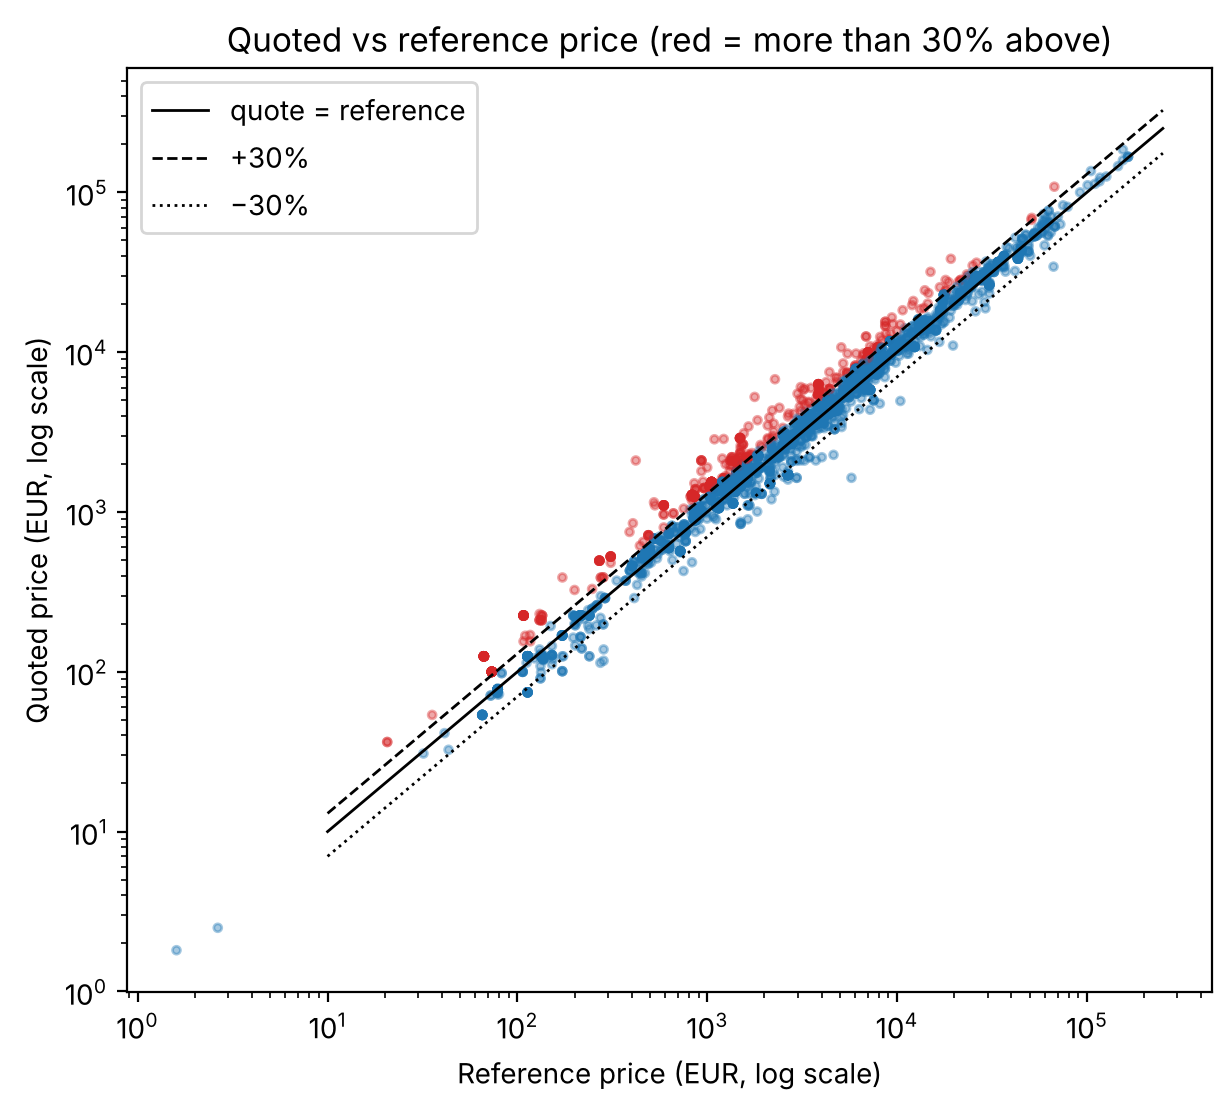

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = prices["over_30"].map({0: "tab:blue", 1: "tab:red"})
ax.scatter(prices[REF], prices[QUOTE], s=8, alpha=0.4, c=colors)
line = np.logspace(1, 5.4, 50)
ax.plot(line, line, "k-", lw=1, label="quote = reference")
ax.plot(line, line * 1.3, "k--", lw=1, label="+30%")
ax.plot(line, line * 0.7, "k:", lw=1, label="−30%")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Reference price (EUR, log scale)")
ax.set_ylabel("Quoted price (EUR, log scale)")
ax.set_title("Quoted vs reference price (red = more than 30% above)")
ax.legend()
plt.show()

On a log scale, the ±30% band has the same width at every price level, which matches the percentage-based question. Over-priced quotes (red) occur across the whole price range, not only for expensive equipment. The original raw-scale scatter plot hides this because most points are compressed near zero.

The same reasoning suggests modelling the **logarithm** of the reference price: a model fitted on the raw EUR scale minimises errors that are dominated by tractors, which is why the original error analysis found ~40% average percentage errors for low-priced items.

### 3.3 How often is the same equipment priced again?

In [7]:
item_counts = prices["item_id"].value_counts()
repeated = prices["item_id"].map(item_counts) > 1

per_item = prices.groupby("item_id")[REF].agg(["count", "nunique"])
multi = per_item[per_item["count"] > 1]

print("Distinct items:", prices["item_id"].nunique())
print(f"Records whose exact item appears more than once: {repeated.mean():.1%}")
print(f"Repeated items that always received the SAME reference price: "
      f"{(multi['nunique'] == 1).mean():.1%}")

Distinct items: 1069
Records whose exact item appears more than once: 80.5%
Repeated items that always received the SAME reference price: 85.2%


**This is the most important EDA finding for modelling.** About 80% of records belong to equipment that appears more than once, and in 85% of those cases the committee reused exactly the same reference price. The reference price behaves like a **price catalogue**: once a model has been priced, the price is reused.

Consequences:

- With a random row-level train/test split, most test records have an identical twin in the training data. A model can score R² ≈ 0,99 by memorising the catalogue. That score says little about equipment the committee has not seen.
- The fairest baseline is not the mean price, but a **catalogue lookup**: "use the reference price this item received before".
- To measure performance on genuinely new equipment, the evaluation must keep each item entirely in the training *or* the test set (`GroupKFold` with `item_id` as the group).

### 3.4 Where does over-pricing happen?

In [8]:
by_supplier = (prices.groupby("Supplier")
               .agg(records=("over_30", "size"), over_30_rate=("over_30", "mean"))
               .query("records >= 40")
               .sort_values("over_30_rate"))
by_supplier

,records,over_30_rate
Supplier,,
Mikro S&E doo,263,0.07
Agro auto doo,1109,0.08
Agromehanika doo,411,0.12
AgroAB doo,108,0.15
Deus group doo,1233,0.19
Agromarket cg doo,190,0.33
Ipko doo,47,0.34


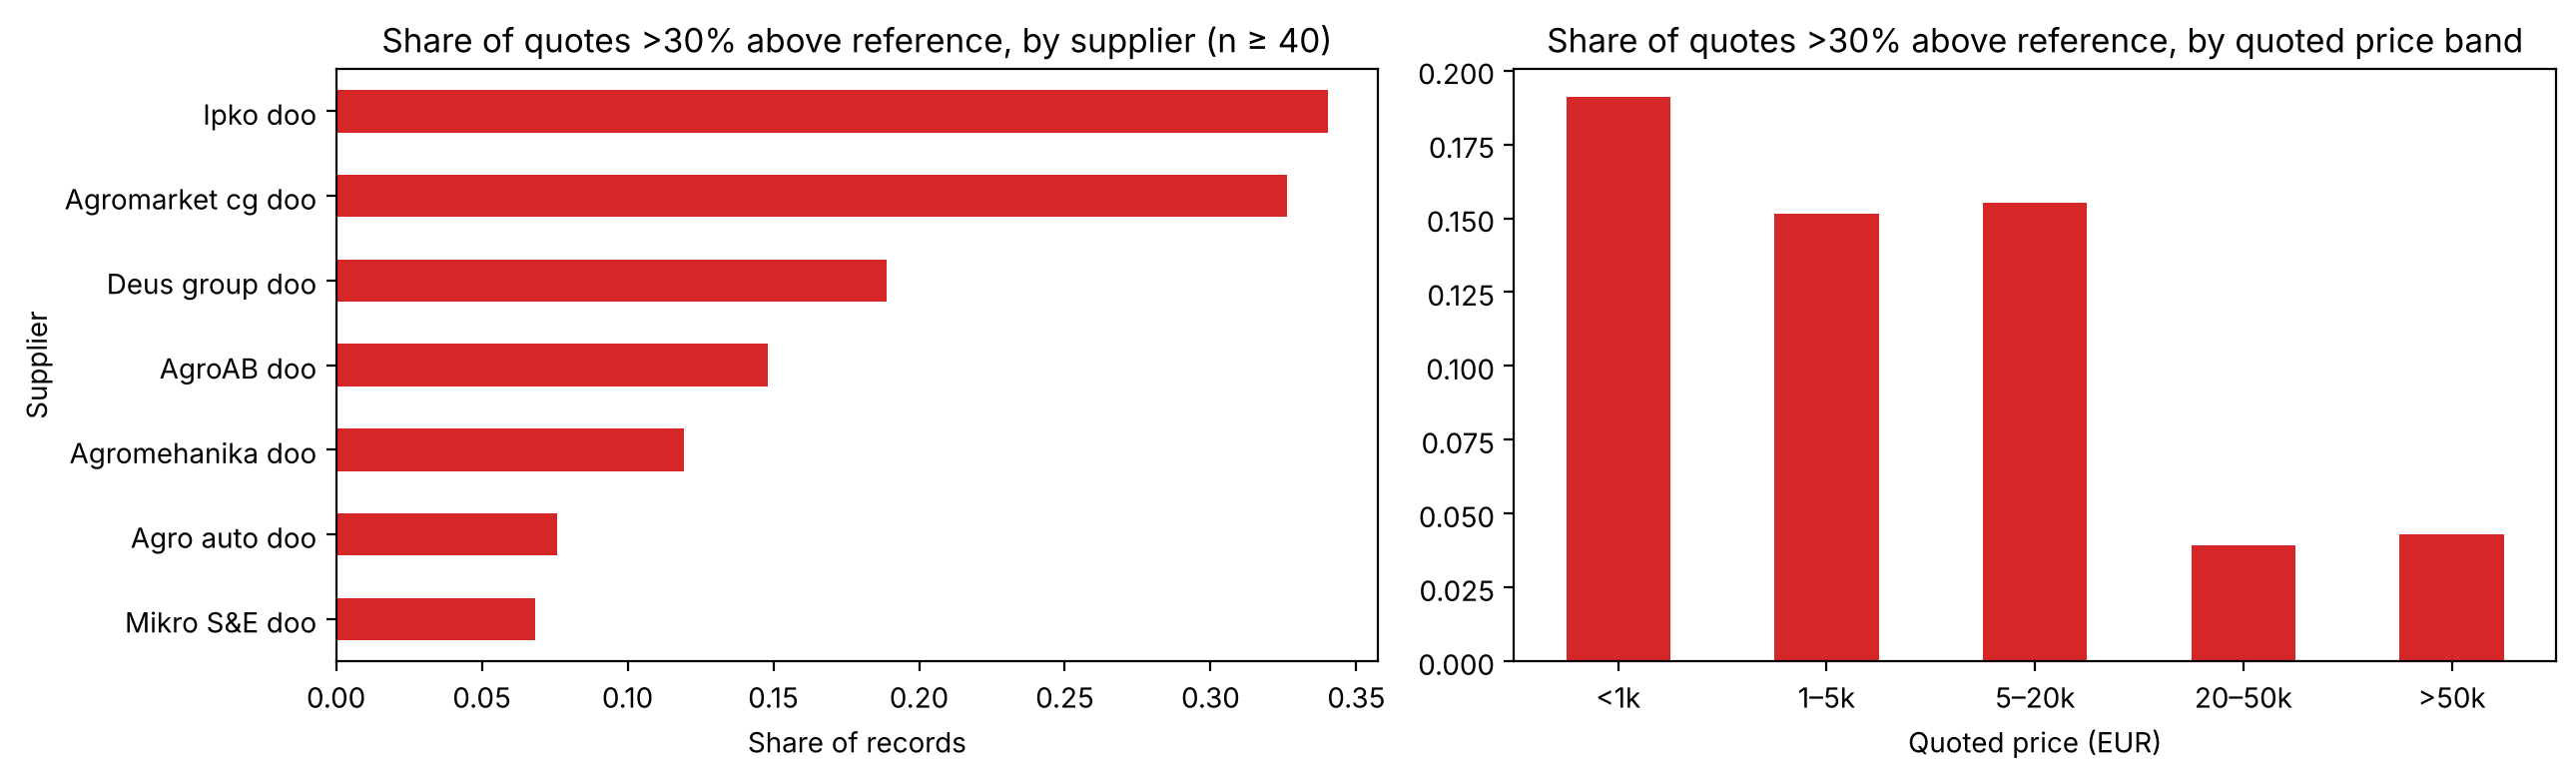

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_supplier["over_30_rate"].plot(kind="barh", ax=axes[0], color="tab:red")
axes[0].set_title("Share of quotes >30% above reference, by supplier (n ≥ 40)")
axes[0].set_xlabel("Share of records")

price_band = pd.cut(prices[QUOTE], [0, 1000, 5000, 20000, 50000, np.inf],
                    labels=["<1k", "1–5k", "5–20k", "20–50k", ">50k"])
prices.groupby(price_band)["over_30"].mean().plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set_title("Share of quotes >30% above reference, by quoted price band")
axes[1].set_xlabel("Quoted price (EUR)"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

Over-pricing rates differ substantially between suppliers (roughly 7% to 34%) and between price bands. The supplier is known when an application is submitted, so it is a legitimate predictor that the original notebooks did not explore.

## 4. Evaluation design

Two evaluation settings are used, because they answer different practical questions:

| Setting | How the data is split | Practical question |
|---|---|---|
| **Known catalogue** | Random 80/20 row split (as in the original notebook) | How well does the system work on a typical new application, where most items have been priced before? |
| **New equipment** | `GroupKFold` by `item_id` | How well can the system price or screen equipment the committee has never seen? |

Decision metrics focus on the over-priced class (`over_30 = 1`):

- **Recall (caught)**: share of over-priced quotes the system flags. A missed one is a *false acceptance*.
- **Precision**: share of flagged quotes that are truly over-priced.
- **Review workload**: share of lines sent to manual review.
- **EUR missed**: the committee's price cuts on over-priced lines that the system would have let through.

`GroupKFold` and percentage-based regression metrics go slightly beyond the course notebooks; see the scikit-learn documentation for `GroupKFold` and `TransformedTargetRegressor`.

In [10]:
groups = prices["item_id"]
gkf = GroupKFold(n_splits=5)

def decision_report(over_true, flagged, label):
    over_true = np.asarray(over_true).astype(bool); flagged = np.asarray(flagged).astype(bool)
    return {"approach": label,
            "over-priced": over_true.sum(),
            "caught": (over_true & flagged).sum(),
            "recall": recall_score(over_true, flagged),
            "precision": precision_score(over_true, flagged, zero_division=0),
            "flagged share": flagged.mean()}

## 5. Why predicting the reference price *from the quote* is circular

The original best model (Ridge, four features including the quote) is reproduced here on the same split (quotes up to 50.000 EUR, `random_state=42`).

In [11]:
under_50k = prices[prices[QUOTE] <= 50000]
train, test = train_test_split(under_50k, test_size=0.2, random_state=42)

ridge4 = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), TEXT_COLS),
        ("num", StandardScaler(), [QUOTE])])),
    ("model", Ridge(alpha=1.0))])
ridge4.fit(train[TEXT_COLS + [QUOTE]], train[REF])
pred = ridge4.predict(test[TEXT_COLS + [QUOTE]])

quote_coef = ridge4.named_steps["model"].coef_[-1] / ridge4.named_steps["prep"].named_transformers_["num"].scale_[0]
print(f"Test R²: {r2_score(test[REF], pred):.4f}  |  MAE: {mean_absolute_error(test[REF], pred):,.2f} EUR")
print(f"Coefficient on the quote: {quote_coef:.3f} EUR of reference per 1 EUR quoted")

Test R²: 0.9932  |  MAE: 308.10 EUR
Coefficient on the quote: 0.936 EUR of reference per 1 EUR quoted


In [12]:
seen = test["item_id"].isin(set(train["item_id"]))
flag_ridge4 = test[QUOTE].values > 1.3 * pred

rows = []
for name, mask in [("item seen in training", seen), ("new item", ~seen)]:
    r = decision_report(test.loc[mask, "over_30"], flag_ridge4[mask.values], name)
    r["records"] = mask.sum()
    r["median % error"] = np.median(np.abs(pred[mask.values] - test.loc[mask, REF]) / test.loc[mask, REF]) * 100
    rows.append(r)
pd.DataFrame(rows).set_index("approach")

,over-priced,caught,recall,precision,flagged share,records,median % error
approach,,,,,,,
item seen in training,85,52,0.61,0.88,0.11,537,1.91
new item,23,0,0.00,0.00,0.05,150,12.97


**Findings**

- The model predicts roughly **0,94 EUR of reference price for every 1 EUR quoted**. The prediction is pulled towards the quote, so the predicted deviation is pulled towards zero, and over-priced quotes look acceptable.
- About 78% of test records are items already seen in training; there the error is small because the one-hot encoding largely memorises the catalogue.
- On **new items**, the model catches **none of the 23 over-priced quotes** in this test set, because its prediction largely follows the quote. This is exactly where decision support is most needed.

The high R² is real, but it measures memorisation of a catalogue plus copying of the quote. It does not show that the model can judge whether a quote is reasonable. This is the main reason for the high number of false acceptances in the original Experiment 1.

### Stability of the original false-acceptance comparison

The original Experiment 2 concluded that the full-data model is preferable because false acceptances fell from 63 to 53. Repeating the original Experiment 1 on different random splits shows how much this number moves on its own:

In [13]:
fa_by_seed = []
for seed in range(10):
    tr, te = train_test_split(under_50k, test_size=0.2, random_state=seed)
    p = ridge4.fit(tr[TEXT_COLS + [QUOTE]], tr[REF]).predict(te[TEXT_COLS + [QUOTE]])
    actual_ok = np.abs(te[QUOTE] - te[REF]) / te[REF] <= 0.30
    pred_ok = (p > 0) & (np.abs(te[QUOTE] - p) / np.where(p > 0, p, 1) <= 0.30)
    fa_by_seed.append(int((~actual_ok & pred_ok).sum()))
print("False acceptances (original ±30% definition) across 10 random splits:", fa_by_seed)

False acceptances (original ±30% definition) across 10 random splits: [43, 33, 43, 45, 52, 43, 55, 46, 53, 34]


False acceptances vary by more than 20 between splits of the same model, so a difference of 10 between two models on one split is within normal variation. Comparisons like this need cross-validation or repeated splits.

## 6. Stage A — catalogue lookup for equipment priced before

In [14]:
catalogue = train.groupby("item_id")[REF].last()        # most recent committee price per item
lookup_ref = test["item_id"].map(catalogue)

print(f"Test records with a catalogue price: {seen.mean():.1%}")
exact = np.isclose(lookup_ref[seen], test.loc[seen, REF])
print(f"Catalogue price exactly equals the committee's reference: {exact.mean():.1%}")
print(f"Lookup MAE on seen items: {mean_absolute_error(test.loc[seen, REF], lookup_ref[seen]):,.2f} EUR")

flag_lookup = test.loc[seen, QUOTE] > 1.3 * lookup_ref[seen]
pd.DataFrame([decision_report(test.loc[seen, "over_30"], flag_ridge4[seen.values], "Ridge (4 features)"),
              decision_report(test.loc[seen, "over_30"], flag_lookup, "Catalogue lookup")]).set_index("approach")

Test records with a catalogue price: 78.2%
Catalogue price exactly equals the committee's reference: 97.2%
Lookup MAE on seen items: 0.72 EUR


,over-priced,caught,recall,precision,flagged share
approach,,,,,
Ridge (4 features),85,52,0.61,0.88,0.11
Catalogue lookup,85,85,1.00,1.00,0.16


For equipment already priced, a lookup table recovers the committee's reference price exactly in about 97% of cases and catches essentially every over-priced quote. No machine learning model is needed for this part; it is a strong **baseline that any model must beat**, and the original notebooks should report it instead of the mean-price baseline.

## 7. Stage B — an independent reference estimate for new equipment

For items with no catalogue price, a reference estimate is built **without the quote**, so that it stays independent of the farmer's offer. Three improvements over the original Experiment 3:

1. **Log target**: `TransformedTargetRegressor` fits on `log(1 + price)` so errors are relative, and predictions can never be negative.
2. **Text features**: character n-grams (TF-IDF) of equipment, brand and model text let the model share information between similar descriptions (e.g. *"S239/1 two-row"* and *"S239/1 two-row with metering unit"*), instead of treating every model string as a separate category.
3. **Extracted specifications**: numbers with units (cm, l, kW, hp, t, kg) are pulled out of the model text as numeric features.

All models are compared with `GroupKFold`, so every prediction is for an item the model has never seen.

In [15]:
UNIT_PATTERNS = {"cm": r"(\d+[\.,]?\d*)\s*cm", "m": r"(\d+[\.,]?\d*)\s*m\b",
                 "l": r"(\d+[\.,]?\d*)\s*l\b", "kw": r"(\d+[\.,]?\d*)\s*kw",
                 "hp": r"(\d+[\.,]?\d*)\s*(?:hp|ks)", "t": r"(\d+[\.,]?\d*)\s*t\b",
                 "kg": r"(\d+[\.,]?\d*)\s*kg"}

def extract_specs(X):
    text = X.iloc[:, 0].str.lower()
    out = pd.DataFrame(index=X.index)
    for unit, pattern in UNIT_PATTERNS.items():
        value = text.str.extract(pattern)[0].str.replace(",", ".").astype(float)
        out[unit] = np.log1p(value.fillna(0))
        out[unit + "_present"] = value.notna().astype(int)
    return out

def join_text(X):
    return (X.iloc[:, 0] + " " + X.iloc[:, 1] + " " + X.iloc[:, 2]).str.lower()

def make_features(use_quote=False, use_supplier=False):
    parts = [
        ("equipment", OneHotEncoder(handle_unknown="ignore", min_frequency=2), ["Equipment / Item"]),
        ("brand", OneHotEncoder(handle_unknown="ignore", min_frequency=2), ["Manufacturer / Brand"]),
        ("text", Pipeline([("join", FunctionTransformer(join_text)),
                           ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4),
                                                     min_df=2, sublinear_tf=True))]), TEXT_COLS),
        ("specs", FunctionTransformer(extract_specs), ["Model / Specifications"])]
    if use_supplier:
        parts.append(("supplier", OneHotEncoder(handle_unknown="ignore"), ["Supplier"]))
    if use_quote:
        parts.append(("log_quote", Pipeline([("log", FunctionTransformer(np.log1p)),
                                             ("scale", StandardScaler())]), [QUOTE]))
    return ColumnTransformer(parts)

def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)

In [16]:
X_all = prices[TEXT_COLS + [QUOTE, "Supplier"]]
y_ref = prices[REF]

reference_models = {
    "Original Exp. 3: Ridge, one-hot, EUR target": Pipeline([
        ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), TEXT_COLS)])),
        ("model", Ridge(alpha=1.0))]),
    "Ridge, one-hot, log target": Pipeline([
        ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), TEXT_COLS)])),
        ("model", log_target(Ridge(alpha=1.0)))]),
    "Ridge, text + specs, log target": Pipeline([
        ("prep", make_features()), ("model", log_target(Ridge(alpha=1.0)))]),
}

rows = []
for name, model in reference_models.items():
    oof = cross_val_predict(model, X_all, y_ref, cv=gkf, groups=groups)
    pct_err = np.abs(oof - y_ref) / y_ref
    rows.append({"model (new items, GroupKFold)": name,
                 "median % error": np.median(pct_err) * 100,
                 "within ±10%": (pct_err <= 0.10).mean(),
                 "within ±30%": (pct_err <= 0.30).mean(),
                 "non-positive predictions": int((oof <= 0).sum())})
pd.DataFrame(rows).set_index("model (new items, GroupKFold)")

,median % error,within ±10%,within ±30%,non-positive predictions
"model (new items, GroupKFold)",,,,
"Original Exp. 3: Ridge, one-hot, EUR target",55.07,0.12,0.30,262
"Ridge, one-hot, log target",27.02,0.23,0.53,0
"Ridge, text + specs, log target",22.39,0.29,0.57,0


In [17]:
# Tune the regularisation strength with grouped cross-validation (course: GridSearch + Pipelines)
ref_search = GridSearchCV(
    Pipeline([("prep", make_features()), ("model", log_target(Ridge()))]),
    param_grid={"model__regressor__alpha": [0.3, 1, 3, 10]},
    cv=gkf, scoring="neg_median_absolute_error")
ref_search.fit(X_all, y_ref, groups=groups)
print("Best alpha:", ref_search.best_params_)

Best alpha: {'model__regressor__alpha': 1}


**Findings**

- The log target removes negative predictions entirely and roughly halves the typical percentage error compared with the original Experiment 3.
- Text and specification features help further, but for unseen equipment the median error remains around **20%**, and only about 55–60% of estimates land within ±30% of the committee's price.
- An error of this size is too close to the ±30% threshold to make a reliable yes/no decision from the estimate alone. It is still useful as an **independent sense-check figure** shown to the committee, alongside the quote.

This is an honest limit of the data: descriptions such as *"M504"* or *"180 cm"* carry too little information to price unseen equipment precisely. Structured specifications or market prices would be needed (see Section 11).

## 8. Stage C — flagging over-priced quotes for new equipment

Rather than estimating a price and then thresholding it, Stage C predicts the decision directly: **the probability that a quote is more than 30% above the reference**.

Using the quote here is not circular. A logistic regression on `log(quote)` plus item features effectively learns "how high is this quote compared with what similar items usually cost", which is exactly the comparison the committee makes. The reference price itself is never an input.

The positive class is about 14% of records, so `class_weight="balanced"` is used and the decision threshold is chosen from cross-validated probabilities (course: *Imbalanced Data*, option 4; *ROC/AUC*).

In [18]:
y_over = prices["over_30"]

flag_models = {
    "LogReg: log(quote) only": Pipeline([
        ("prep", ColumnTransformer([("log_quote", Pipeline([("log", FunctionTransformer(np.log1p)),
                                                            ("scale", StandardScaler())]), [QUOTE])])),
        ("model", LogisticRegression(class_weight="balanced", max_iter=3000))]),
    "LogReg: item text + specs + log(quote)": Pipeline([
        ("prep", make_features(use_quote=True)),
        ("model", LogisticRegression(class_weight="balanced", max_iter=3000))]),
    "LogReg: item text + specs + log(quote) + supplier": Pipeline([
        ("prep", make_features(use_quote=True, use_supplier=True)),
        ("model", LogisticRegression(class_weight="balanced", max_iter=3000))]),
    "Random Forest: item text + specs + log(quote) + supplier": Pipeline([
        ("prep", make_features(use_quote=True, use_supplier=True)),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                         class_weight="balanced", n_jobs=-1, random_state=42))]),
}

rows, oof_probs = [], {}
for name, model in flag_models.items():
    proba = cross_val_predict(model, X_all, y_over, cv=gkf, groups=groups, method="predict_proba")[:, 1]
    oof_probs[name] = proba
    rows.append({"model (new items, GroupKFold)": name,
                 "ROC-AUC": roc_auc_score(y_over, proba),
                 "PR-AUC": average_precision_score(y_over, proba),
                 "recall @0.5": recall_score(y_over, proba >= 0.5),
                 "precision @0.5": precision_score(y_over, proba >= 0.5),
                 "flagged @0.5": (proba >= 0.5).mean()})
pd.DataFrame(rows).set_index("model (new items, GroupKFold)")

,ROC-AUC,PR-AUC,recall @0.5,precision @0.5,flagged @0.5
"model (new items, GroupKFold)",,,,,
LogReg: log(quote) only,0.62,0.20,0.64,0.21,0.44
LogReg: item text + specs + log(quote),0.82,0.42,0.70,0.40,0.26
LogReg: item text + specs + log(quote) + supplier,0.83,0.45,0.70,0.42,0.24
Random Forest: item text + specs + log(quote) + supplier,0.80,0.39,0.50,0.45,0.16


In [19]:
# For comparison: the original approach (Ridge with the quote, then threshold at +30%) on new items
oof_ridge4 = cross_val_predict(ridge4, X_all, y_ref, cv=gkf, groups=groups)
pd.DataFrame([decision_report(y_over, prices[QUOTE] > 1.3 * oof_ridge4, "Original: Ridge with quote → threshold"),
              decision_report(y_over, oof_probs["LogReg: item text + specs + log(quote) + supplier"] >= 0.5,
                              "Direct flag: logistic regression")]).set_index("approach")

,over-priced,caught,recall,precision,flagged share
approach,,,,,
Original: Ridge with quote → threshold,506,110,0.22,0.23,0.14
Direct flag: logistic regression,506,355,0.70,0.42,0.24


**Findings**

- The quote alone has little screening power (ROC-AUC ≈ 0,6); combined with item text and supplier, logistic regression reaches **ROC-AUC ≈ 0,83** on equipment it has never seen.
- At a 0,5 threshold it catches about **70% of over-priced quotes while flagging about a quarter of lines**, compared with under 30% caught by the original regression-then-threshold approach in the same setting.
- Logistic regression outperforms Random Forest here, which is common with many sparse text features and a few thousand rows.

## 9. The complete decision-support system vs the original approach

The full system combines the stages:

1. **Item priced before** → use the catalogue reference price; compute the committee's capped price automatically and flag the line if it is more than 30% over.
2. **New item** → flag probability from Stage C. Lines above the threshold go to the committee; the Stage B estimate is shown as an independent reference figure.

The threshold for new items is chosen **on the training data only** (grouped cross-validated probabilities), targeting at least 80% recall. Everything is then evaluated on the same type of random 80/20 split as the original notebook, repeated over five seeds and using all 3.505 records.

In [20]:
FLAG_FEATURES = TEXT_COLS + [QUOTE, "Supplier"]

def committee_cut(df):
    # Euros the committee removed from the quote (quote minus final capped price)
    cap = np.where(df[QUOTE] < 1000, 1.15, 1.10)
    return df[QUOTE] - np.minimum(df[QUOTE], df[REF] * cap)

def choose_threshold(train_df, target_recall=0.80):
    model = Pipeline([("prep", make_features(use_quote=True, use_supplier=True)),
                      ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
    proba = cross_val_predict(model, train_df[FLAG_FEATURES], train_df["over_30"],
                              cv=GroupKFold(5), groups=train_df["item_id"], method="predict_proba")[:, 1]
    for t in np.arange(0.95, 0.05, -0.01):
        if recall_score(train_df["over_30"], proba >= t) >= target_recall:
            return round(t, 2)
    return 0.5

def evaluate_split(seed):
    train, test = train_test_split(prices, test_size=0.2, random_state=seed)
    over = test["over_30"].values.astype(bool)
    cut = committee_cut(test).values

    # Original approach: Ridge with quote; predicted outside ±30% -> review, else accept quote
    p = ridge4.fit(train[TEXT_COLS + [QUOTE]], train[REF]).predict(test[TEXT_COLS + [QUOTE]])
    orig_review = ~((p > 0) & (np.abs(test[QUOTE] - p) / np.where(p > 0, p, 1) <= 0.30)).values
    orig_flag_over = test[QUOTE].values > 1.3 * p

    # Hybrid system
    catalogue = train.groupby("item_id")[REF].last()
    lookup = test["item_id"].map(catalogue).values
    seen = ~np.isnan(lookup)
    threshold = choose_threshold(train)
    flagger = Pipeline([("prep", make_features(use_quote=True, use_supplier=True)),
                        ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
    flagger.fit(train[FLAG_FEATURES], train["over_30"])
    proba = flagger.predict_proba(test[FLAG_FEATURES])[:, 1]
    hyb_flag = np.where(seen, test[QUOTE].values > 1.3 * np.nan_to_num(lookup, nan=1), proba >= threshold)
    hyb_review = ~seen & (proba >= threshold)          # only new, flagged items need a human

    return {"seed": seed, "threshold (new items)": threshold, "over-priced": over.sum(),
            "original: caught": (over & orig_flag_over).sum(),
            "hybrid: caught": (over & hyb_flag).sum(),
            "original: false flags": (~over & orig_flag_over).sum(),
            "hybrid: false flags": (~over & hyb_flag).sum(),
            "original: lines to review": orig_review.sum(),
            "hybrid: lines to review": hyb_review.sum(),
            "original: EUR missed": cut[over & ~orig_flag_over].sum(),
            "hybrid: EUR missed": cut[over & ~hyb_flag].sum(),
            "EUR cut on over-priced lines": cut[over].sum()}

results = pd.DataFrame([evaluate_split(s) for s in range(5)]).set_index("seed")
results

,threshold (new items),over-priced,original: caught,hybrid: caught,original: false flags,hybrid: false flags,original: lines to review,hybrid: lines to review,original: EUR missed,hybrid: EUR missed,EUR cut on over-priced lines
seed,,,,,,,,,,,
0,0.30,100,61,92,12,45,101,59,"81,202.55","21,942.57","115,454.07"
1,0.37,111,64,104,23,43,108,51,"76,081.47","10,141.67","124,617.09"
2,0.19,103,74,97,21,55,120,72,"47,655.50","5,619.83","97,414.11"
3,0.19,110,60,104,21,63,113,82,"81,604.12","16,016.77","111,054.77"
4,0.30,110,58,102,22,50,98,65,"114,170.48","59,467.46","149,125.25"


In [21]:
summary = results.mean().to_frame("mean over 5 splits")
summary.loc["original: recall"] = (results["original: caught"] / results["over-priced"]).mean()
summary.loc["hybrid: recall"] = (results["hybrid: caught"] / results["over-priced"]).mean()
summary

,mean over 5 splits
threshold (new items),0.27
over-priced,106.80
original: caught,63.40
hybrid: caught,99.80
original: false flags,19.80
hybrid: false flags,51.20
original: lines to review,108.00
hybrid: lines to review,65.80
original: EUR missed,"80,142.82"
hybrid: EUR missed,"22,637.66"


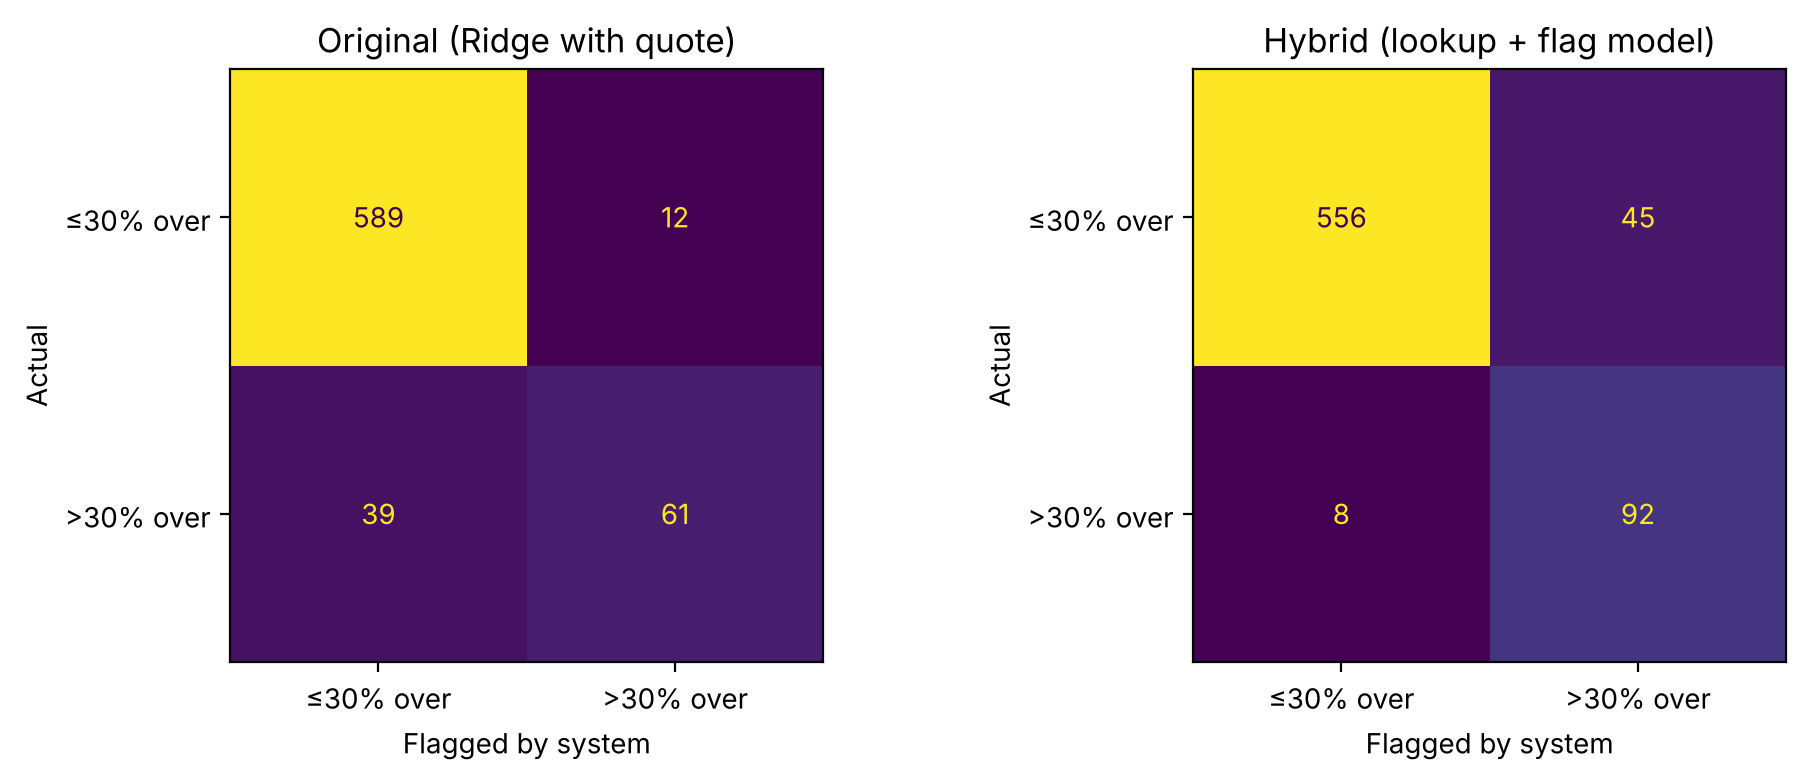

In [22]:
# Confusion matrices for one split (seed 0), original vs hybrid
train, test = train_test_split(prices, test_size=0.2, random_state=0)
p = ridge4.fit(train[TEXT_COLS + [QUOTE]], train[REF]).predict(test[TEXT_COLS + [QUOTE]])
catalogue = train.groupby("item_id")[REF].last(); lookup = test["item_id"].map(catalogue).values
seen = ~np.isnan(lookup); t = choose_threshold(train)
flagger = Pipeline([("prep", make_features(use_quote=True, use_supplier=True)),
                    ("model", LogisticRegression(class_weight="balanced", max_iter=3000))]
                   ).fit(train[FLAG_FEATURES], train["over_30"])
proba = flagger.predict_proba(test[FLAG_FEATURES])[:, 1]
hyb = np.where(seen, test[QUOTE].values > 1.3 * np.nan_to_num(lookup, nan=1), proba >= t)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, flags, title in [(axes[0], test[QUOTE].values > 1.3 * p, "Original (Ridge with quote)"),
                         (axes[1], hyb, "Hybrid (lookup + flag model)")]:
    ConfusionMatrixDisplay(confusion_matrix(test["over_30"], flags),
                           display_labels=["≤30% over", ">30% over"]).plot(ax=ax, colorbar=False)
    ax.set_title(title); ax.set_xlabel("Flagged by system"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

**Findings**

- Across five random splits, the hybrid system catches about **93% of over-priced quotes**, compared with about **60%** for the original approach.
- It raises more false flags (about 51 vs 20 per split), because the new-item threshold is set for high recall. Even so, **fewer lines need human review** (about 66 vs 108), because catalogue items are handled automatically.
- Of roughly 120.000 EUR the committee cut from over-priced lines per test split, the original approach would have let about **80.000 EUR** through unflagged; the hybrid system about **23.000 EUR**, almost all of it on new equipment.
- The threshold for new items can be moved to trade review workload against missed euros (course: *Imbalanced Data*, *ROC/AUC*, and the *ROI* exercise for costing the trade-off).

## 10. Interpretation — answering the research question

**Can we tell whether a quoted mechanization price is within ±30% of a reasonable reference price?**

- **For equipment the committee has priced before (≈80% of lines): yes, reliably.** The historical reference price is effectively a catalogue, and a lookup reproduces it almost exactly. The committee's own cap rule can then be applied automatically.
- **For new equipment: only as a screening aid.** No model in this notebook estimates the reference price of unseen equipment precisely enough to make a ±30% decision on its own (median error ≈ 20%). A direct over-pricing classifier can rank risky quotes well (ROC-AUC ≈ 0,83) and send a manageable share of lines to the committee.

**Are the original metrics evidence of a viable system?** Not on their own. R² ≈ 0,99 mainly reflects catalogue memorisation and the use of the quote as a feature. The decision metrics on new equipment are what determine viability, and they show the original approach misses most over-priced quotes there.

Human oversight remains essential, and the committee keeps responsibility for every final price.

## 11. Limitations and next steps

- **Item identity is approximate.** `item_id` uses lower-cased text; spelling variants of the same model may still sit in both training and test sets, so new-item results may be slightly optimistic. Grouping by equipment family + brand + model prefix would be stricter.
- **No time information.** If records were ordered by date, a time-based split (train on earlier, test on later) would be the most realistic evaluation and would show how quickly the catalogue goes out of date.
- **Unit prices and quantities.** A few lines are priced per metre or per piece (e.g. sprayer hose at 1,60 EUR), and repeated identical lines within one application are probably quantities rather than data-entry duplicates. A quantity column would make both clearer.
- **Partly untranslated text.** Some descriptions remain in Montenegrin (e.g. *"nagrtača"*, *"REALNA"*); translating or standardising them would improve the text features.
- **The 37 evaluation notes** ("Reasonable price", "REALNA" = realistic) say the committee accepted the quote. They cannot train the reference-price model, but they are valid *negative* examples for the over-pricing classifier.
- **Structured specifications and market prices** (power, working width, capacity, year, list prices) are the most valuable additions for pricing new equipment.
- **Alternative target:** the committee caps any quote above reference +10/15%, not just those above +30%. A classifier for *"will this line be capped?"* would match the committee's real workload even more closely.